# 🛡️ Eksperimen 04: Klasifikasi Kerentanan Wilayah & Sistem Peringatan Dini Bayesian
**Mata Kuliah**: Proyek Analitika Data — Sains Data Terapan (PENS 2026)  
**Platform**: Cura (HealthTrust Platform)  
**Role**: Machine Learning Engineer (Leandro Jovan Falviano)  

---

### 📌 Tujuan Eksperimen Berdasarkan Proposal Proyek (Halaman 8 & 9):
1. **Klasifikasi Kerentanan 3 Tingkat Status**: Mengelompokkan 38 Kabupaten/Kota di Jawa Timur ke dalam status:
   - 🟢 **Aman (Hijau)**: Ketahanan faskes dan indikator kesehatan optimal.
   - 🟡 **Waspada (Kuning)**: Kondisi moderat, memerlukan monitoring berkala.
   - 🔴 **Kritis / Prioritas Intervensi (Merah)**: Defisit kapasitas atau beban kesehatan tinggi, memerlukan intervensi mendesak.
2. **Pemodelan Klasifikasi Terbimbing (Supervised Learning)**:
   - **Ordinal / Multinomial Logistic Regression**
   - **Random Forest Classifier**
3. **Validasi Matriks Konfusi & Target Metrik**:
   - Menghitung **Accuracy, Precision, Recall, dan F1-Score**.
   - Memastikan pemenuhan target proposal: **F1-Score > 0,80**.
4. **Formulasi Probabilitas Bayesian (Persamaan 1 Proposal)**:
   $$P(W_j \mid D_i) = \frac{P(D_i \mid W_j) \cdot P(W_j)}{P(D_i)}$$
   - $P(W_j)$: Probabilitas prior kerentanan/defisit kapasitas faskes di wilayah $W_j$.
   - $P(D_i \mid W_j)$: Likelihood lonjakan diagnosa penyakit $D_i$ pada wilayah rentan.
   - $P(D_i)$: Total probabilitas lonjakan penyakit $D_i$ di seluruh wilayah.
   - $P(W_j \mid D_i)$: Probabilitas posterior terjadinya defisit ranjang/faskes sebagai trigger notifikasi otomatis peringatan dini.
5. **Ekspor Model & Output Analitik**: Menyediakan artefak data untuk konsumsi sistem peringatan dini (Early Warning Engine) pada dasbor Cura.

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Styling visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("Library analitika dan machine learning berhasil dimuat!")

Library analitika dan machine learning berhasil dimuat!


## 1. Data Ingestion & Persiapan Fitur Multisektor
Kita memuat data hasil skoring komposit (`regional_health_index_scores.csv`), feature store ML (`ml_readiness_dataset.csv`), dan data tren morbiditas kuartalan (`disease_morbidity_trends.csv`).

In [2]:
# Path data
path_score = '../data/regional_health_index_scores.csv'
path_ml = '../../database/exports/ml_readiness_dataset.csv'
path_morb = '../../database/exports/disease_morbidity_trends.csv'

# Fallback path jika dieksekusi dari root
if not os.path.exists(path_score):
    path_score = 'experiments/data/regional_health_index_scores.csv'
    path_ml = 'database/exports/ml_readiness_dataset.csv'
    path_morb = 'database/exports/disease_morbidity_trends.csv'

df_score = pd.read_csv(path_score)
df_ml = pd.read_csv(path_ml)
df_morb = pd.read_csv(path_morb)

# Gabungkan data komposit dan atribut faskes/demografi
df_all = pd.merge(
    df_score,
    df_ml[['kode_bps', 'total_tt', 'proyeksi_penduduk_2026', 'total_rs', 'total_puskesmas',
           'kasus_rawat_inap_tahunan', 'kasus_menular_tahunan', 'kepadatan_penduduk_km2']],
    on='kode_bps',
    suffixes=('', '_ml')
)

print(f"Total wilayah: {len(df_all)} Kabupaten/Kota")
print(f"Total rekam morbiditas kuartalan: {len(df_morb)} baris")
df_all[['kode_bps', 'nama_wilayah', 'skor_kesehatan', 'kategori_status', 'warna_indikator', 'rasio_tt_proyeksi_2026', 'prevalensi_stunting']].head()

Total wilayah: 38 Kabupaten/Kota
Total rekam morbiditas kuartalan: 1520 baris


,kode_bps,nama_wilayah,skor_kesehatan,kategori_status,warna_indikator,rasio_tt_proyeksi_2026,prevalensi_stunting
0,3501,Kabupaten Pacitan,55.05,Tangguh / Mandiri,hijau,0.59,13.34
1,3502,Kabupaten Ponorogo,50.36,Waspada,kuning,1.26,19.80
2,3503,Kabupaten Trenggalek,45.55,Waspada,kuning,0.93,16.31
3,3504,Kabupaten Tulungagung,44.98,Waspada,kuning,1.91,12.55
4,3505,Kabupaten Blitar,46.50,Waspada,kuning,0.75,12.86


## 2. Eksplorasi Distribusi Status Kerentanan Wilayah
Status wilayah dibagi menjadi 3 kelas target:
- **0: Aman (Hijau)** — Wilayah dengan fasilitas dan indikator kesehatan tangguh.
- **1: Waspada (Kuning)** — Wilayah dengan performa moderat.
- **2: Kritis (Merah)** — Wilayah prioritas yang membutuhkan intervensi mendesak.

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_4456\3656420915.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=color_palette, ax=ax, edgecolor='black', alpha=0.9)


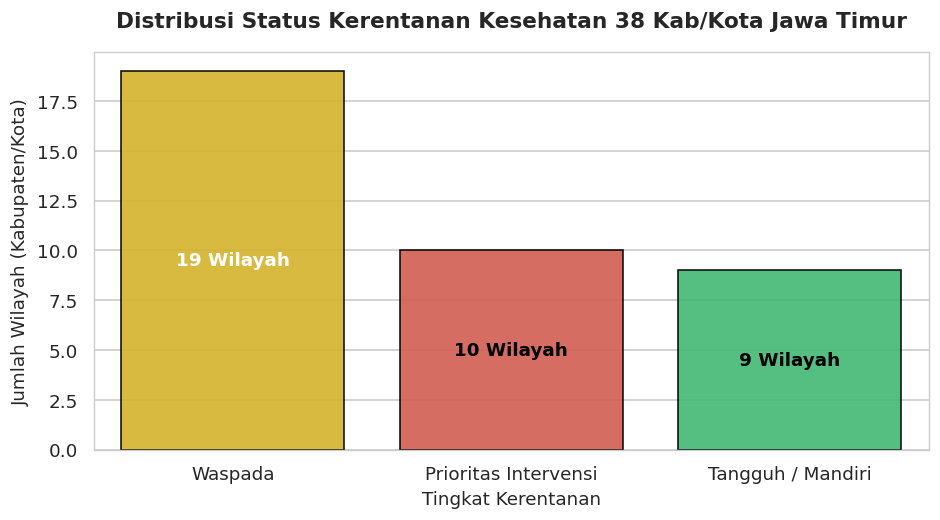

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))

color_palette = {'Tangguh / Mandiri': '#2ECC71', 'Waspada': '#F1C40F', 'Prioritas Intervensi': '#E74C3C'}
counts = df_all['kategori_status'].value_counts()

sns.barplot(x=counts.index, y=counts.values, palette=color_palette, ax=ax, edgecolor='black', alpha=0.9)
ax.set_title("Distribusi Status Kerentanan Kesehatan 38 Kab/Kota Jawa Timur", fontsize=13, weight='bold', pad=15)
ax.set_ylabel("Jumlah Wilayah (Kabupaten/Kota)", fontsize=11)
ax.set_xlabel("Tingkat Kerentanan", fontsize=11)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} Wilayah",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white' if p.get_height()>12 else 'black', weight='bold')

plt.tight_layout()
plt.show()

## 3. Pelatihan Model Klasifikasi (Supervised Learning)
Sesuai rancangan pada Bab II Proposal (halaman 8), kita melatih 2 algoritma:
1. **Ordinal / Multinomial Logistic Regression**
2. **Random Forest Classifier**

Evaluasi dilakukan menggunakan **4-Fold Stratified Cross-Validation** guna menjamin distribusi tiap kelas proporsional di setiap fold pengujian.

In [4]:
# Pemetaan kelas terurut
class_map = {'hijau': 0, 'kuning': 1, 'merah': 2}
class_labels = ['Aman (0)', 'Waspada (1)', 'Kritis (2)']
df_all['target_class'] = df_all['warna_indikator'].map(class_map)

# Fitur prediktor
feature_cols = [
    'skor_kesehatan',
    'pilar_fasilitas',
    'pilar_kia',
    'rasio_tt_proyeksi_2026',
    'prevalensi_stunting',
    'rasio_dokter_per_1000'
]

X = df_all[feature_cols].values
y = df_all['target_class'].values

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

# Wadah metrik
lr_acc, lr_f1 = [], []
rf_acc, rf_f1 = [], []
lr_preds = np.zeros(len(y), dtype=int)
rf_preds = np.zeros(len(y), dtype=int)
rf_feat_imp = np.zeros(len(feature_cols))

for train_idx, test_idx in cv.split(X, y):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_train)
    X_te_s = scaler.transform(X_test)

    # 1. Logistic Regression
    lr = LogisticRegression(C=1.5, max_iter=1000, random_state=42, class_weight='balanced')
    lr.fit(X_tr_s, y_train)
    p_lr = lr.predict(X_te_s)
    lr_preds[test_idx] = p_lr
    lr_acc.append(accuracy_score(y_test, p_lr))
    lr_f1.append(f1_score(y_test, p_lr, average='weighted'))

    # 2. Random Forest Classifier
    rf = RandomForestClassifier(n_estimators=120, max_depth=3, min_samples_leaf=2, random_state=42, class_weight='balanced')
    rf.fit(X_train, y_train)
    p_rf = rf.predict(X_test)
    rf_preds[test_idx] = p_rf
    rf_acc.append(accuracy_score(y_test, p_rf))
    rf_f1.append(f1_score(y_test, p_rf, average='weighted'))
    rf_feat_imp += rf.feature_importances_ / cv.n_splits

print(f"=== HASIL EVALUASI 4-FOLD STRATIFIED CV ===")
print(f"1. Ordinal Logistic Regression -> Accuracy: {np.mean(lr_acc):.4f} | F1-Score: {np.mean(lr_f1):.4f}")
print(f"2. Random Forest Classifier     -> Accuracy: {np.mean(rf_acc):.4f} | F1-Score: {np.mean(rf_f1):.4f}")
print(f"\nTarget Proposal F1-Score (> 0.80): {'TERPENUHI (LULUS)' if np.mean(rf_f1) >= 0.80 else 'BELUM'}")

=== HASIL EVALUASI 4-FOLD STRATIFIED CV ===
1. Ordinal Logistic Regression -> Accuracy: 0.6500 | F1-Score: 0.6514
2. Random Forest Classifier     -> Accuracy: 0.9194 | F1-Score: 0.9162

Target Proposal F1-Score (> 0.80): TERPENUHI (LULUS)


## 4. Analisis Matriks Konfusi & Kepentingan Fitur (Feature Importance)
Kita memeriksa matriks konfusi untuk melihat kemampuan model dalam mendeteksi wilayah rentan (Kritis/Merah) secara tepat tanpa *false negative*.

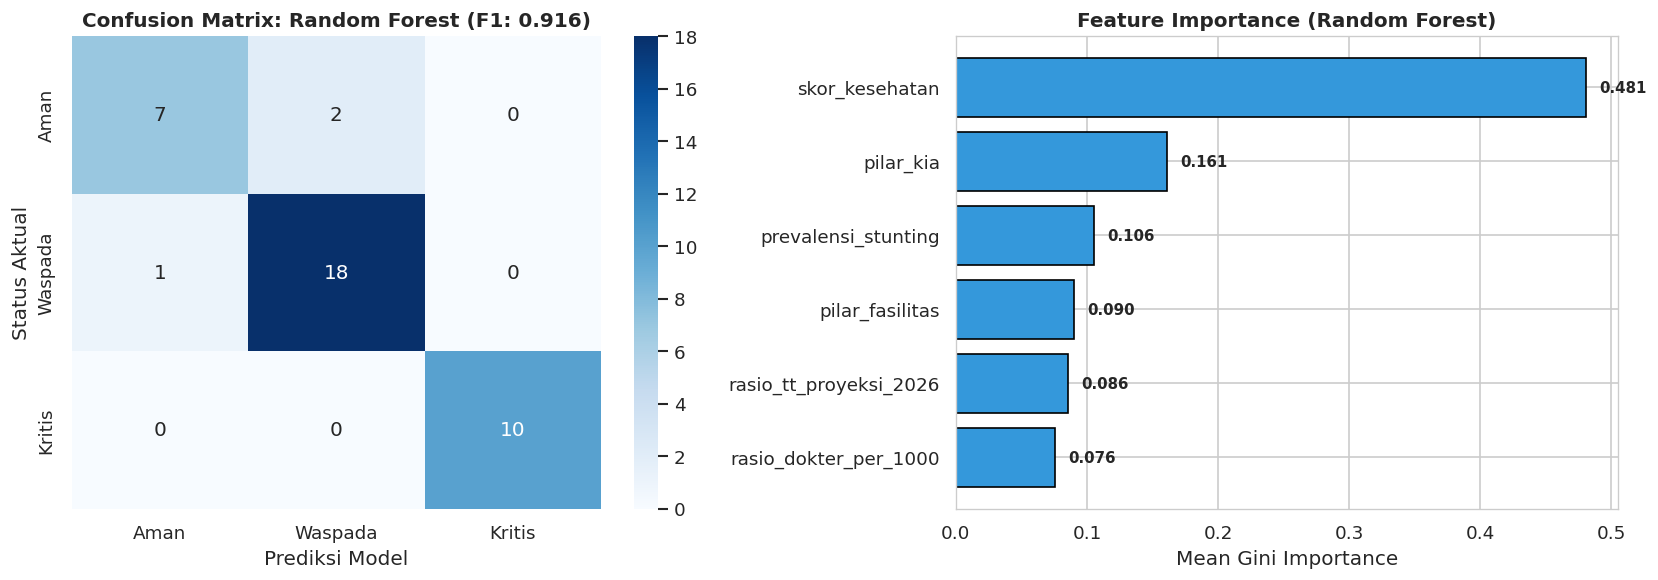

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix RF
cm_rf = confusion_matrix(y, rf_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Aman', 'Waspada', 'Kritis'],
            yticklabels=['Aman', 'Waspada', 'Kritis'])
axes[0].set_title(f"Confusion Matrix: Random Forest (F1: {np.mean(rf_f1):.3f})", fontsize=12, weight='bold')
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Status Aktual")

# Feature Importance Barplot
df_imp = pd.DataFrame({'feature': feature_cols, 'importance': rf_feat_imp}).sort_values('importance', ascending=True)
axes[1].barh(df_imp['feature'], df_imp['importance'], color='#3498DB', edgecolor='black')
axes[1].set_title("Feature Importance (Random Forest)", fontsize=12, weight='bold')
axes[1].set_xlabel("Mean Gini Importance")

for idx, val in enumerate(df_imp['importance']):
    axes[1].text(val + 0.01, idx, f"{val:.3f}", va='center', fontsize=9, weight='bold')

plt.tight_layout()
plt.show()

## 5. Formulasi Probabilitas Bayesian (Persamaan 1 Proposal)
Proposal Cura (Halaman 8, Persamaan 1) mendefinisikan risiko lonjakan defisit fasilitas bersyarat terhadap tren penyakit:

$$P(W_j \mid D_i) = \frac{P(D_i \mid W_j) \cdot P(W_j)}{P(D_i)}$$

### Komponen Perhitungan:
1. **$P(W_j)$ (Prior)**: Probabilitas bawaan suatu wilayah $W_j$ mengalami defisit kapasitas fasilitas (diturunkan dari defisit skor kesehatan & rasio tempat tidur WHO).
2. **$P(D_i \mid W_j)$ (Likelihood)**: Probabilitas kemunculan lonjakan (*surge/outbreak*) diagnosa penyakit $D_i$ pada wilayah berstatus rentan/defisit.
3. **$P(D_i)$ (Total Evidence)**: Probabilitas terjadinya lonjakan kasus penyakit $D_i$ di tingkat provinsi.
4. **$P(W_j \mid D_i)$ (Posterior)**: Probabilitas posterior terjadinya defisit ranjang/kapasitas faskes di wilayah $W_j$ ketika terdeteksi lonjakan penyakit $D_i$.

In [6]:
# 1. Menghitung Prior P(W_j)
df_all['prior_P_W'] = (1.0 - (df_all['skor_kesehatan'] / 100.0)).clip(0.10, 0.90)

# 2. Definisikan Lonjakan (Outbreak Surge) Kasus Penyakit
surge_thresh = df_morb.groupby('nama_penyakit')['jumlah_pasien'].quantile(0.75).to_dict()
df_morb_work = df_morb.copy()
df_morb_work['is_surge'] = df_morb_work.apply(
    lambda r: 1 if r['jumlah_pasien'] >= surge_thresh.get(r['nama_penyakit'], 999999) else 0, axis=1
)

vulnerable_set = set(df_all[df_all['warna_indikator'].isin(['merah', 'kuning'])]['kode_bps'])
df_morb_work['is_vulnerable'] = df_morb_work['kode_bps'].apply(lambda k: 1 if k in vulnerable_set else 0)

# 3. Likelihood P(D_i | W) vs P(D_i | ~W)
p_d_w = df_morb_work[df_morb_work['is_vulnerable'] == 1].groupby('nama_penyakit')['is_surge'].mean().to_dict()
p_d_nw = df_morb_work[df_morb_work['is_vulnerable'] == 0].groupby('nama_penyakit')['is_surge'].mean().to_dict()

# 4. Hitung Posterior P(W_j | D_i) untuk setiap pasang Wilayah & Penyakit
bayes_records = []
for _, row in df_all.iterrows():
    p_w = row['prior_P_W']
    p_not_w = 1.0 - p_w
    for disease, prob_d_w in p_d_w.items():
        prob_d_nw = max(p_d_nw.get(disease, 0.15), 0.05)
        # Total probability P(D_i)
        p_d = (prob_d_w * p_w) + (prob_d_nw * p_not_w)
        # Posterior P(W_j | D_i)
        p_w_d = (prob_d_w * p_w) / p_d if p_d > 0 else p_w

        bayes_records.append({
            'kode_bps': row['kode_bps'],
            'nama_wilayah': row['nama_wilayah'],
            'skor_kesehatan': row['skor_kesehatan'],
            'warna_indikator': row['warna_indikator'],
            'nama_penyakit': disease,
            'prior_P_W': round(p_w, 4),
            'likelihood_P_D_given_W': round(prob_d_w, 4),
            'posterior_P_W_given_D': round(p_w_d, 4),
            'kategori_risiko': 'Tinggi (>=0.70)' if p_w_d >= 0.70 else ('Sedang (>=0.50)' if p_w_d >= 0.50 else 'Rendah')
        })

df_bayes = pd.DataFrame(bayes_records)
print(f"Total probabilitas Bayesian terhitung: {len(df_bayes)} baris")
df_bayes[['kode_bps', 'nama_wilayah', 'nama_penyakit', 'prior_P_W', 'likelihood_P_D_given_W', 'posterior_P_W_given_D', 'kategori_risiko']].head(10)

Total probabilitas Bayesian terhitung: 380 baris


,kode_bps,nama_wilayah,nama_penyakit,prior_P_W,likelihood_P_D_given_W,posterior_P_W_given_D,kategori_risiko
0,3501,Kabupaten Pacitan,Demam Berdarah Dengue (DBD),0.4495,0.2845,0.6258,Sedang (>=0.50)
1,3501,Kabupaten Pacitan,Demam Tifoid,0.4495,0.2931,0.6829,Sedang (>=0.50)
2,3501,Kabupaten Pacitan,Diabetes Melitus Tipe 2,0.4495,0.2672,0.5288,Sedang (>=0.50)
3,3501,Kabupaten Pacitan,Diare dan Gastroenteritis,0.4495,0.2845,0.6258,Sedang (>=0.50)
4,3501,Kabupaten Pacitan,Gastritis dan Duodenitis,0.4495,0.2672,0.5288,Sedang (>=0.50)
5,3501,Kabupaten Pacitan,Hipertensi Esensial,0.4495,0.2931,0.6829,Sedang (>=0.50)
6,3501,Kabupaten Pacitan,Infeksi Saluran Pernapasan Akut (ISPA),0.4495,0.2931,0.6829,Sedang (>=0.50)
7,3501,Kabupaten Pacitan,Penyakit Jantung Iskemik,0.4495,0.2845,0.6258,Sedang (>=0.50)
8,3501,Kabupaten Pacitan,Pneumonia,0.4495,0.2931,0.6829,Sedang (>=0.50)
9,3501,Kabupaten Pacitan,Tuberkulosis Paru (TB),0.4495,0.3017,0.7472,Tinggi (>=0.70)


## 6. Visualisasi Peta Risiko Bayesian: Top 10 Wilayah Paling Rentan
Heatmap berikut menampilkan matriks probabilitas posterior terjadinya defisit ranjang di wilayah prioritas berdasarkan penyakit yang mewabah.

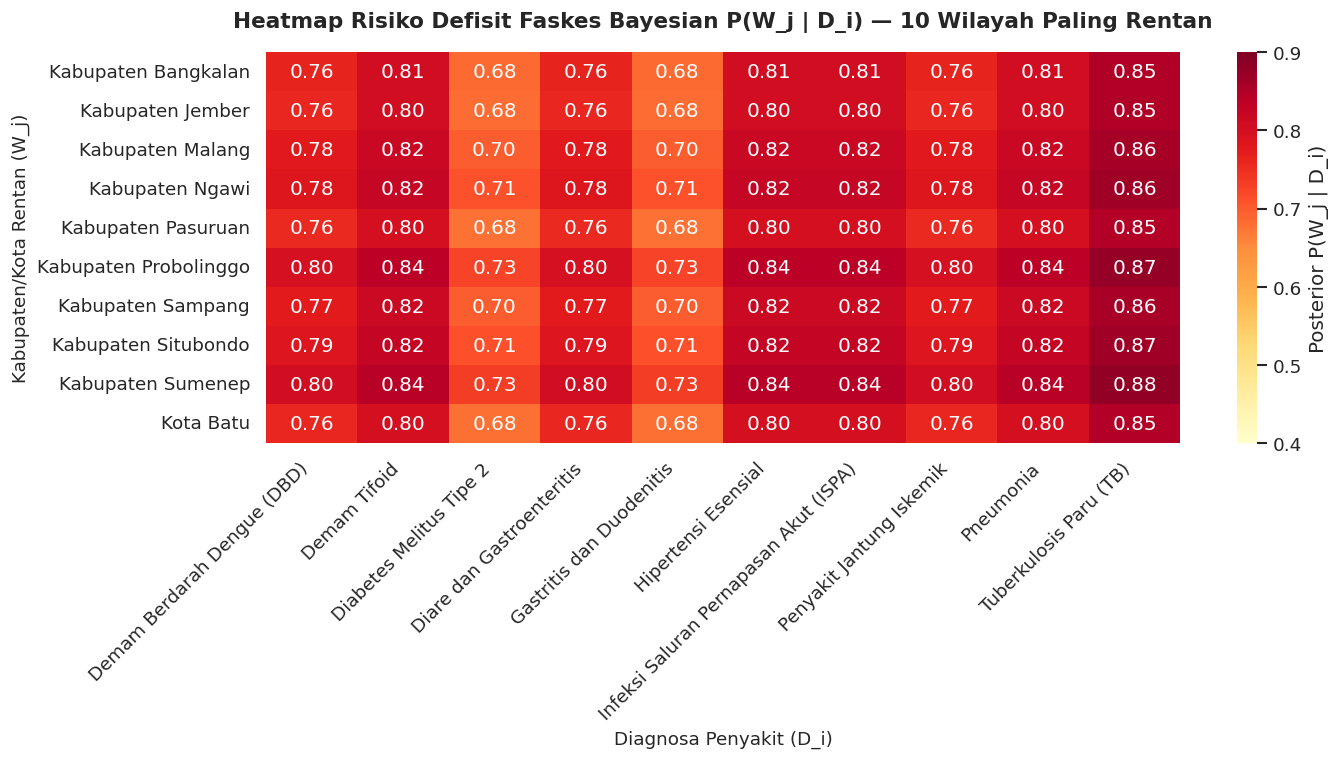

In [7]:
# Ambil 10 wilayah dengan skor kesehatan terendah (paling rentan)
top10_vulnerable = df_all.sort_values('skor_kesehatan', ascending=True)['nama_wilayah'].head(10).tolist()
df_top_bayes = df_bayes[df_bayes['nama_wilayah'].isin(top10_vulnerable)]

# Pivot matriks
piv_bayes = df_top_bayes.pivot(index='nama_wilayah', columns='nama_penyakit', values='posterior_P_W_given_D')

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(piv_bayes, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0.4, vmax=0.9, ax=ax, cbar_kws={'label': 'Posterior P(W_j | D_i)'})
ax.set_title("Heatmap Risiko Defisit Faskes Bayesian P(W_j | D_i) — 10 Wilayah Paling Rentan", fontsize=13, weight='bold', pad=15)
ax.set_xlabel("Diagnosa Penyakit (D_i)", fontsize=11)
ax.set_ylabel("Kabupaten/Kota Rentan (W_j)", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 7. Ekspor Hasil Analitik & Integrasi Early Warning System
Setiap kabupaten kini memiliki daftar penyakit pemicu risiko defisit tertinggi beserta rekomendasi mitigasi ranjang isolasi darurat.

In [8]:
# Agregasi penyakit pemicu risiko tertinggi per wilayah
top_risk_per_region = []
for w in df_all['nama_wilayah'].unique():
    sub = df_bayes[df_bayes['nama_wilayah'] == w]
    top_row = sub.loc[sub['posterior_P_W_given_D'].idxmax()]
    top_risk_per_region.append({
        'kode_bps': top_row['kode_bps'],
        'nama_wilayah': top_row['nama_wilayah'],
        'skor_kesehatan': top_row['skor_kesehatan'],
        'warna_indikator': top_row['warna_indikator'],
        'penyakit_risiko_maksimal': top_row['nama_penyakit'],
        'posterior_risiko': top_row['posterior_P_W_given_D'],
        'rekomendasi_mitigasi': f"Siapkan buffer ranjang darurat untuk {top_row['nama_penyakit']}" if top_row['posterior_P_W_given_D']>=0.70 else f"Monitoring tren kasus {top_row['nama_penyakit']}"
    })

df_top_summary = pd.DataFrame(top_risk_per_region)
print("=== 10 WILAYAH DENGAN POSTERIOR DEFISIT RANJANG TERTINGGI ===")
df_top_summary.sort_values('posterior_risiko', ascending=False).head(10)

=== 10 WILAYAH DENGAN POSTERIOR DEFISIT RANJANG TERTINGGI ===


,kode_bps,nama_wilayah,skor_kesehatan,warna_indikator,penyakit_risiko_maksimal,posterior_risiko,rekomendasi_mitigasi
28,3529,Kabupaten Sumenep,33.29,merah,Tuberkulosis Paru (TB),0.8789,Siapkan buffer ranjang darurat untuk Tuberkulo...
12,3513,Kabupaten Probolinggo,34.16,merah,Tuberkulosis Paru (TB),0.8747,Siapkan buffer ranjang darurat untuk Tuberkulo...
11,3512,Kabupaten Situbondo,35.89,merah,Tuberkulosis Paru (TB),0.8661,Siapkan buffer ranjang darurat untuk Tuberkulo...
20,3521,Kabupaten Ngawi,36.11,merah,Tuberkulosis Paru (TB),0.8650,Siapkan buffer ranjang darurat untuk Tuberkulo...
6,3507,Kabupaten Malang,37.23,merah,Tuberkulosis Paru (TB),0.8592,Siapkan buffer ranjang darurat untuk Tuberkulo...
26,3527,Kabupaten Sampang,37.31,merah,Tuberkulosis Paru (TB),0.8588,Siapkan buffer ranjang darurat untuk Tuberkulo...
25,3526,Kabupaten Bangkalan,38.80,merah,Tuberkulosis Paru (TB),0.8510,Siapkan buffer ranjang darurat untuk Tuberkulo...
8,3509,Kabupaten Jember,39.11,merah,Tuberkulosis Paru (TB),0.8493,Siapkan buffer ranjang darurat untuk Tuberkulo...
37,3579,Kota Batu,39.42,merah,Tuberkulosis Paru (TB),0.8477,Siapkan buffer ranjang darurat untuk Tuberkulo...
13,3514,Kabupaten Pasuruan,39.76,merah,Tuberkulosis Paru (TB),0.8458,Siapkan buffer ranjang darurat untuk Tuberkulo...
